In [191]:
import numpy as np

class Distance:
    """
    Ways to calculate distances between particles
    """

    def prepare(self, particles, weights=None):
        """
        Calculate and cache any objects which will be repeatedly used,
        but only need calculation once.
        """
        pass

    def pairwise_distance(self, x, y):
        """
        Distance between two particles
        
        x: numpy.ndarray
        y: numpy.ndarray
        """
        raise NotImplementedError

    def distances_from(self, particles, idx):
        """
        Distances from particle with index idx to every particle,
        including the particle itself.
        """
        raise NotImplementedError

    def nearest_neighbours_idx(self, particles, idx, k):
        """
        Return indices of k nearest neighbours,
        excluding the particle itself.
        """

        distances = self.distances_from(particles, idx)
        neighbours = np.argsort(distances)
        neighbours = neighbours[neighbours != idx]

        return neighbours[:k]

class EuclidDistance(Distance):
    """
    Euclidean distance:

    d(x, y) = sqrt( Σ_i (x_i - y_i)^2 )
    """
    def pairwise_distance(self, x, y):
        diff = x - y
        return np.sqrt(diff @ diff)

    def distances_from(self, particles, idx):
        return np.linalg.norm(particles - particles[idx], axis=1)

class ScaledDistance(Distance):
    """
    Each dimension, i, is scaled by a characteristic lengthscale, L_i.
    Scaled distance is then Euclidean distance in these normalised units

    d(x, y) = sqrt( Σ_i ((x_i - y_i)/L_i)^2 )
    """

    def __init__(self, lengthscales):
        self.lengthscales = lengthscales

    def pairwise_distance(self, x, y):
        x_scaled = x / self.lengthscales
        y_scaled = y / self.lengthscales

        diff = x_scaled - y_scaled
        return np.sqrt(diff @ diff)

    def distances_from(self, particles, idx):
        particles_scaled = particles / self.lengthscales
        return np.linalg.norm(particles_scaled - particles_scaled[idx], axis=1)
    
class MahalanobisDistance(Distance):
    """
    Mahalanobis distance using the weighted covariance
    of the current particle population.

    d(x, y) = sqrt( (x-y)^T Σ^{-1} (x-y) )
    """

    def __init__(self, regularisation=1e-10):
        self.regularisation = regularisation
        self._inv_cov = None

    def prepare(self, particles, weights=None):
        """
        Estimate covariance and cache its inverse.
        """

        if weights is None:
            cov = np.cov(particles.T)
        else:
            mean = np.average(particles, axis=0, weights=weights)
            centred = particles - mean
            cov = np.einsum("i,ij,ik->jk", weights, centred, centred)

        # numerical stabilisation
        cov += self.regularisation * np.eye(cov.shape[0])
        self._inv_cov = np.linalg.inv(cov)

    def pairwise_distance(self, x, y):
        if self._inv_cov is None:
            raise(RuntimeError("prepare() must have been called previously"))

        diff = x - y

        return np.sqrt(diff @ self._inv_cov @ diff)

    def distances_from(self, particles, idx):
        if self._inv_cov is None:
            raise(RuntimeError("prepare() must have been called previously"))
        diff = particles - particles[idx]
        tmp = diff @ self._inv_cov

        return np.sqrt(np.sum(tmp * diff, axis=1))

In [192]:
rng = np.random.default_rng(seed = 0)

means = np.array([0, 0])
stds = np.array([1, 10])

cov = np.array([
    [stds[0], 0.95],
    [0.95, stds[1]]
])

particles = rng.multivariate_normal(means, cov, size=100)

In [193]:
x = particles[1, :]
y = particles[5, :]

idx = 5
k = 10

In [194]:
dist = EuclidDistance()

dist.prepare(particles)
dist.pairwise_distance(x, y)
dist.distances_from(particles, 1)
nearest_euclid = dist.nearest_neighbours_idx(particles, idx, k)

In [195]:
dist = ScaledDistance(lengthscales=stds)

dist.prepare(particles)
dist.pairwise_distance(x, y)
dist.distances_from(particles, 1)
nearest_scaled = dist.nearest_neighbours_idx(particles, idx, k)

In [196]:
dist = MahalanobisDistance()

dist.prepare(particles)
dist.pairwise_distance(x, y)
dist.distances_from(particles, 1)
nearest_mahal = dist.nearest_neighbours_idx(particles, idx, k)

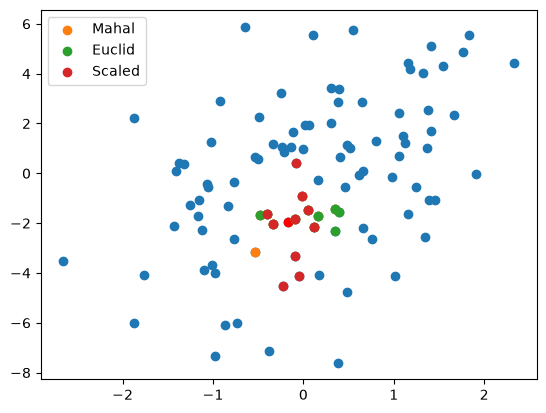

In [197]:
import matplotlib.pyplot as plt

plt.scatter(particles[:, 0], particles[:, 1])
plt.scatter(particles[idx, 0], particles[idx, 1], color="red")
plt.scatter(particles[nearest_mahal, 0], particles[nearest_mahal, 1], label="Mahal")
plt.scatter(particles[nearest_euclid, 0], particles[nearest_euclid, 1], label="Euclid")
plt.scatter(particles[nearest_scaled, 0], particles[nearest_scaled, 1], label="Scaled")
plt.legend()
plt.show()